# Active subspaces of a human ventricular myocyte model under virtual drugs (CiPAORdv1.0)

Data from a new computation following

J. Parikh, P. Di Achille, J. Kozloski and V. Gurev, *Global Sensitivity Analysis of Ventricular Myocyte
Model-Derived Metrics for Proarrhythmic Risk Assessment*, Frontiers in Pharmacology 10:1054, 2019.

IBM T.J. Watson Research Center, Yorktown, NY, United States.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import cipaord_driver as cm
import generate_data as gd

SEED = 1054                       # the only seed in this notebook (bootstraps)
t_start = time.perf_counter()
NAMES = cm.NAMES
labels = [r'$b_{\rm INa}$', r'$b_{\rm INaL}$', r'$b_{\rm Ito}$', r'$b_{\rm IKs}$', r'$b_{\rm ICaL}$',
          r'$b_{\rm IK1}$', r'$sb_{\rm IKr}$', r'$V_{\rm half}$', r'$K_u$']
QOIS = cm.QOI_NAMES               # qNet, APD90, APD50, peakVm, diastolicCa, peakCa, CaTD50, CaTD90
UNITS = dict(zip(QOIS, cm.QOI_UNITS))

## Summary

The CiPAORdv1.0 human ventricular endocardial myocyte model, paced 1000 beats at 2000 ms, was run at 224
virtual drugs drawn from the nine-input box of Parikh et al. (2019): six percent channel blocks and three
hERG drug-binding parameters. Seven of the eight features studied in the paper have a one-dimensional active
subspace, with $\lambda_1/\lambda_2$ from 8.3 (CaTD90) to 46.1 (peakCa), 24.3 for qNet and 14.1 for APD90
(for CaTD90 and peakVm the second gap is close, $\lambda_2/\lambda_3$ = 6.4 and 7.3), while CaTD50 has a
two-dimensional one ($\lambda_2/\lambda_3 = 12.7$ against $\lambda_1/\lambda_2 = 4.9$); a cubic in the active
variables has a leave-one-out $R^2$ of 0.972 for qNet and 0.951 for APD90 (one variable) and 0.956 for CaTD50
(two). The in-sample linear-regression $R^2$ of the paper's Table 4 is reproduced to within 0.01 for six of
eight features (the two Ca-transient durations are lower, outside their bootstrap intervals), and the Sobol'
indices of a quadratic fit match the paper's qNet shares (bINaL 0.39, sbIKr 0.26, bICaL 0.15, bINa 0.13
against 40, 26, 16 and 13 %).

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with a density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap
after the $n$-th eigenvalue means that $f$ changes mostly along $n$ linear combinations of the inputs,
the active variables $\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, and a sufficient summary plot of $f$
against $\mathbf{y}$ shows it. Without gradients, the global quadratic estimator (QPHD) fits a
least-squares quadratic $f \approx c + \mathbf{g}^\top\mathbf{x} + \mathbf{x}^\top\mathbf{A}\mathbf{x}$
in normalized inputs and uses the matrix $\mathbf{g}\mathbf{g}^\top + \tfrac{4}{3}\mathbf{A}^2$, which is
$\mathbf{C}$ of the quadratic on $[-1,1]^m$. See P. G. Constantine, *Active Subspaces: Emerging Ideas for
Dimension Reduction in Parameter Studies*, SIAM, 2015,
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**CiPAORdv1.0, endocardial cell** (the model of the paper, p. 3): the O'Hara-Rudy human ventricular
myocyte (O'Hara et al. 2011) with the Hodgkin-Huxley IKr replaced by a hERG Markov model with dynamic
drug binding and trapping (Li et al. 2017), and five conductances rescaled by Dutta et al. (2017)
(GKr ×1.114/1.1, GNaL ×2.661, GKs ×1.870, GK1 ×1.698, PCa ×1.007). The 48 physiological ODE states
(membrane potential, gates, Na/K/Ca concentrations in myoplasm, subspace and SR, CaMKII, RyR release,
nine hERG states) satisfy

$$C_m \frac{dV}{dt} = -\Big(I_{\rm Na} + I_{\rm NaL} + I_{\rm to} + I_{\rm CaL} + I_{\rm CaNa} + I_{\rm CaK}
+ I_{\rm Kr} + I_{\rm Ks} + I_{\rm K1} + I_{\rm NaCa} + I_{\rm NaK} + I_{\rm Nab} + I_{\rm Kb} + I_{\rm pCa}
+ I_{\rm Cab} + I_{\rm stim}\Big),$$

with $I_{\rm Kr} = G_{\rm Kr}\sqrt{K_o/5.4}\;O\,(V - E_K)$, $O$ the open state of the hERG model.

**Virtual drug** (paper Eqs 1–3). A percent block $b$ of current $X \in \{$INa, INaL, Ito, IKs, ICaL, IK1$\}$
scales its maximal conductance (permeability for ICaL) by $(100 - b)/100$. The hERG drug enters through
the binding rate $K_u\,sb_{\rm IKr}$ from the open and inactivated-open states
(O → O*, IO → IO*), the unbinding rate $K_u$ (O* → O; $K_u k_{53}/k_{63}$ for IO* → IO), and trapping
O*, IO* ⇄ C* at rates $K_t = 3.5\times10^{-5}$ ms$^{-1}$ and $K_t/(1 + e^{-(V - V_{\rm half})/6.789})$, so that
$sb_{\rm IKr} = K_{\max}C^h/(C^h + IC_{50}^h)$ is the ratio of bound to open channels at equilibrium.

**Protocol** (paper p. 4): 1000 beats at a cycle length of 2000 ms (bradycardia), stimulus −80 µA/µF for
0.5 ms, starting from the control steady state distributed with CiPAORdv1.0. The features (paper Table 3)
are read from beat 1000; definitions as in the FDA code: **qNet** = ∫ (INaL + ICaL + Ito + IKr + IKs +
IK1) dt over the beat (nC/µF); **APD90/APD50** from max dV/dt to the 90 %/50 % repolarisation crossing;
**peakVm**; **diastolicCa** and **peakCa** (nM); **CaTD50/CaTD90**. The model is a Myokit file,
`cipaord_endo.mmt`, a re-expression of CiPAORdv1.0: its ORd core follows the O'Hara–Rudy reference
implementation as distributed in the FDA code (BSD 3-clause, copyright T. O'Hara and Y. Rudy; the notice is
in the file's header and in `LICENSE-ORd`), and its hERG/drug-binding section is written in flux form from
Li et al. (2017), with parameter values from the FDA files. Its right-hand sides were compared with the FDA C code
(agreement to 1.5e-12; an external run, not reproducible from the repository, DATA.md). The paper's unpublished "minor modifications"
of the FDA code are not known; what is assumed is listed in DATA.md.

The nine inputs (Table 2, p. 3), uniform on a linear scale as the paper's Saltelli sample:

In [2]:
desc = {'bINa': 'block of fast Na current INa', 'bINaL': 'block of late Na current INaL',
        'bIto': 'block of transient outward current Ito', 'bIKs': 'block of slow delayed rectifier IKs',
        'bICaL': 'block of L-type Ca current ICaL', 'bIK1': 'block of inward rectifier IK1',
        'sbIKr': 'static hERG block component (binding rate Ku*sbIKr)',
        'Vhalf': 'hERG drug trapping (half-trapping voltage)', 'Ku': 'hERG drug unbinding rate'}
print(f"{'input':6s} {'units':5s} {'Myokit constant':16s} {'lower':>7s} {'upper':>6s}  description")
for (n, var, lo, hi, u) in cm.INPUTS:
    print(f'{n:6s} {u:5s} {var:16s} {lo:7.4g} {hi:6.4g}  {desc[n]}')
print(f'\nprotocol: CL {cm.CL:g} ms, stimulus -80 uA/uF for 0.5 ms at the start of each beat, '
      f'{cm.N_BEATS} beats from the control steady state; features of beat {cm.N_BEATS}; '
      f'EAD and repolarisation checks on the last {cm.N_LAST} beats; CVODES tolerances '
      f'abs {gd.ABS_TOL:g}, rel {gd.REL_TOL:g}')

input  units Myokit constant    lower  upper  description
bINa   %     drug.bINa              0     80  block of fast Na current INa
bINaL  %     drug.bINaL             0     80  block of late Na current INaL
bIto   %     drug.bIto              0     80  block of transient outward current Ito
bIKs   %     drug.bIKs              0     80  block of slow delayed rectifier IKs
bICaL  %     drug.bICaL             0     80  block of L-type Ca current ICaL
bIK1   %     drug.bIK1              0     80  block of inward rectifier IK1
sbIKr  -     drug.sbIKr             0      4  static hERG block component (binding rate Ku*sbIKr)
Vhalf  mV    drug.Vhalf          -200     -1  hERG drug trapping (half-trapping voltage)
Ku     1/ms  drug.Ku            1e-05      1  hERG drug unbinding rate

protocol: CL 2000 ms, stimulus -80 uA/uF for 0.5 ms at the start of each beat, 1000 beats from the control steady state; features of beat 1000; EAD and repolarisation checks on the last 5 beats; CVODES tolerance

## Load the data

`cipaord_virtual_drugs.csv` holds one row per run of `generate_data.py`: the first 224 points of one
scrambled Sobol' sequence (scipy, seed 1054) of 256 points on the Table 2 box.

In [3]:
D = np.loadtxt('cipaord_virtual_drugs.csv', delimiter=',')
col = {c: j for j, c in enumerate(gd.COLS)}
resp = D[:, col['response']].astype(int)
print(f'{D.shape[0]} rows x {D.shape[1]} columns: 9 inputs, 8 features of beat 1000, '
      f'{len(gd.EXTRA)} checks, response, cpu_s')
print('responses: normal', int(np.sum(resp == 0)), '| EAD', int(np.sum(resp == 1)),
      '| no full repolarisation', int(np.sum(resp == 2)))

224 rows x 27 columns: 9 inputs, 8 features of beat 1000, 8 checks, response, cpu_s
responses: normal 224 | EAD 0 | no full repolarisation 0


### Abnormal runs and the rows used

Runs are flagged, never dropped: response 1 marks an early afterdepolarisation (plateau dV/dt > 0, the
FDA code's test) in any of beats 996–1000 (the file stores the count `n_EAD` for these five beats and the largest plateau dV/dt, `max_dv`, of beat 1000 only), response 2 a beat without full repolarisation. The notebook uses
response 0 only. The cell prints how many runs that rule removes; if it removes none, the rows used are the
whole Sobol' design and the uniform law is not distorted.

In [4]:
assert np.allclose(D[:, :9], gd.design(), rtol=1e-9, atol=1e-12)   # the rows are the Sobol' design
space = ac.Uniform(cm.LOWER, cm.UPPER, names=NAMES)    # uniform on the Table 2 box, as sampled
ZN = space.to_normalized(D[:, :9])                     # [-1, 1]^9
keep = resp == 0                                       # the rule: normal response in beats 996-1000
mdv = D[:, col['max_dv']]
print(f'EAD beats in beats 996-1000, summed over runs: {int(D[:, col["n_EAD"]].sum())}; '
      f'beats without full repolarisation: {int(D[:, col["n_norepol"]].sum())}')
print(f'largest plateau dV/dt (30% repolarisation to APD90) in beat 1000, over all runs: '
      f'{mdv.max():.3f} mV/ms (an EAD needs > 0); median {np.median(mdv):.3f}')
j = int(np.argmax(mdv))
print(f'  at row {j}: ' + ', '.join(f'{n} {v:.3g}' for n, v in zip(NAMES, D[j, :9]))
      + f'; APD90 {D[j, col["APD90"]]:.0f} ms')
print(f'qNet below 0 in {int(np.sum(D[:, col["qNet"]] < 0))} rows (min {D[:, col["qNet"]].min():.2f} nC/uF); '
      f'APD90 range [{D[:, col["APD90"]].min():.0f}, {D[:, col["APD90"]].max():.0f}] ms')
dvm = D[:, col['dVdt_max']]
stim = np.abs(dvm - 80) < 0.01                         # 80 mV/ms = the stimulus alone (80 uA/uF over C_m = 1 uF/cm^2)
print(f'rows whose max dV/dt is the stimulus slope (80 mV/ms): {int(stim.sum())}, at bINa '
      f'{D[stim, 0].min():.0f} to {D[stim, 0].max():.0f} %; max dV/dt over the other rows: '
      f'{dvm[~stim].min():.1f} to {dvm[~stim].max():.1f} mV/ms')
print(f'rows excluded by the rule: {int(np.sum(~keep))}')
X = D[keep, :9]
F = {q: D[keep, col[q]] for q in QOIS}
XN = ZN[keep]
M = len(X)
print(f'\nM = {M} rows used; QPHD needs (m+1)(m+2)/2 = {10 * 11 // 2} coefficients')

EAD beats in beats 996-1000, summed over runs: 0; beats without full repolarisation: 0
largest plateau dV/dt (30% repolarisation to APD90) in beat 1000, over all runs: -0.088 mV/ms (an EAD needs > 0); median -0.228
  at row 26: bINa 36.6, bINaL 3.21, bIto 44.9, bIKs 71, bICaL 10.8, bIK1 8.51, sbIKr 3.92, Vhalf -35.1, Ku 0.916; APD90 720 ms
qNet below 0 in 2 rows (min -1.75 nC/uF); APD90 range [203, 779] ms
rows whose max dV/dt is the stimulus slope (80 mV/ms): 4, at bINa 74 to 80 %; max dV/dt over the other rows: 80.0 to 276.4 mV/ms
rows excluded by the rule: 0

M = 224 rows used; QPHD needs (m+1)(m+2)/2 = 55 coefficients


No run was abnormal: no run has an EAD in beats 996–1000 (`n_EAD` = 0), and the largest plateau dV/dt of beat 1000
over all 224 runs is −0.088 mV/ms (median −0.228), so no row is excluded and the 224 rows are the full Sobol' design, with no skew of the uniform law.
In this box the model does not reach EADs on its own, consistent with the paper, which provokes EADs only by
an additional hERG reduction (its ThEAD,hERG protocol, which is not part of this data set). Two rows have a
slightly negative qNet (minimum −1.75 nC/µF); qNet is a net charge and may have either sign, so they are kept.
In 4 rows, all with bINa between 74 and 80 %, the largest dV/dt of the beat is the stimulus slope itself (80 mV/ms): the INa
upstroke is slower than the stimulus, so `dVdt_max` is not the upstroke velocity there, and APD90 and APD50 are
timed from the stimulus onset. This follows the FDA definition (time of max dV/dt); `dVdt_max` is not analysed.

### Cost and convergence of the 1000-beat train

Each run also records qNet and APD90 of beat 500 and the spread of both over beats 996–1000, so the
cell below measures how far the 1000-beat train is from a periodic steady state, and prints the cost.

In [5]:
cpu = D[:, col['cpu_s']]
print(f'cost: {cpu.mean():.1f} s CPU per run of 1000 beats (min {cpu.min():.1f}, max {cpu.max():.1f}); '
      f'{cpu.sum() / 60:.0f} min CPU for {len(D)} runs')
for q in ('qNet', 'APD90'):
    d = D[keep, col[q]] - D[keep, col[q + '_b500']]
    rel = np.abs(d) / np.abs(D[keep, col[q]])
    sd = F[q].std()
    print(f'{q}: beat 1000 - beat 500: median |d| {np.median(np.abs(d)):.3g} {UNITS[q]}, max {np.abs(d).max():.3g} '
          f'(median relative {np.median(rel):.1e}, max {rel.max():.1e}); max |d| / sd(beat 1000) = {np.abs(d).max() / sd:.3f}')
    s = D[keep, col[q + '_spread']]
    print(f'      spread over beats 996-1000: median {np.median(s):.2g}, max {s.max():.2g} {UNITS[q]}')

cost: 24.4 s CPU per run of 1000 beats (min 19.8, max 31.5); 91 min CPU for 224 runs
qNet: beat 1000 - beat 500: median |d| 0.0763 nC/uF, max 0.498 (median relative 1.4e-03, max 2.2e-02); max |d| / sd(beat 1000) = 0.021
      spread over beats 996-1000: median 0.0047, max 0.11 nC/uF
APD90: beat 1000 - beat 500: median |d| 0.0473 ms, max 0.438 (median relative 1.1e-04, max 6.9e-04); max |d| / sd(beat 1000) = 0.004
      spread over beats 996-1000: median 0.037, max 0.67 ms


A run costs 24.4 s of CPU on average (19.8–31.5 s), 91 min for the design. The train is settled: between
beats 500 and 1000 qNet changes by a median 0.076 nC/µF (at most 0.50, 2.1 % of its standard deviation over
the rows) and APD90 by a median 0.047 ms (at most 0.44 ms). The change over the last five beats is at most
0.11 nC/µF and 0.67 ms, well below the spread of the data.

## Estimate the active subspace

There are no gradients (each run is 1000 beats of a stiff ODE), so the subspace is estimated from values
with the global quadratic estimator (`estimator='qphd'`), which needs at least $(m+1)(m+2)/2 = 55$ rows,
with a 500-replicate bootstrap (`rng=SEED`). The space is the uniform law on the Table 2 box; X is passed
in physical units and v1 normalizes it to $[-1, 1]^9$. The paper reports that linear regression explains
83–97 % of the variance of the features (Table 4), so the linear least-squares estimator (`'ols'`, one
direction) is a cross-check, and the table prints the linear $R^2$ for comparison with Table 4 (in-sample,
as in the paper, with its leave-one-out value beside it) and the leave-one-out $R^2$ of the quadratic.
**Dimension.** v1's default rule (`evg`) takes the largest *linear* gap $\lambda_k - \lambda_{k+1}$, which
favours $k = 1$ whenever $\lambda_1$ is large. We choose $n$ by the largest *ratio* $\lambda_k/\lambda_{k+1}$
among the leading three ($k = 1, 2, 3$), and print the bootstrap share of replicates in which
$\lambda_2/\lambda_3 > \lambda_1/\lambda_2$. The ratio over all $k$ (`evg` with `gap='log'`) is also printed;
it is pulled to $k = 8$ by the near-null tail of the QPHD spectrum for three features, so it is not used.
The leading eigenvectors are signed so that $f$ increases with $y_1$ and $y_2$ (`ac.orient`; the paper
has no active subspace figures).

In [6]:
def lin_r2(f):
    # R^2 of the least-squares linear fit in the 9 inputs (in-sample, as the paper's Table 4).
    A = np.column_stack([np.ones(M), XN])
    r = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
    return 1 - r @ r / np.sum((f - f.mean())**2)


def quad_features(Z):
    m = Z.shape[1]
    cols = [np.ones(len(Z))] + [Z[:, j] for j in range(m)]
    cols += [Z[:, j] * Z[:, k] for j in range(m) for k in range(j, m)]
    return np.column_stack(cols)


def loo_r2(A, f):
    # Leave-one-out R^2 of the least-squares fit with design matrix A (hat-matrix formula).
    H = A @ np.linalg.pinv(A)
    e = (f - H @ f) / (1 - np.diag(H))
    return 1 - e @ e / np.sum((f - f.mean())**2)


def top(w, k=3):
    return ', '.join(f'{NAMES[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:k])


A_lin = np.column_stack([np.ones(M), XN])
Q = quad_features(XN)
subs, ols, r2lin, n_use = {}, {}, {}, {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for q in QOIS:
        s = ac.active_subspace(space=space, X=X, f=F[q], estimator='qphd', nboot=500, rng=SEED, qoi=q)
        s = ac.orient(s, by='covariance', X=X, f=F[q], columns=2)
        ols[q] = ac.active_subspace(space=space, X=X, f=F[q], estimator='ols', qoi=q)
        r2lin[q] = lin_r2(F[q])
        lam = s.eigenvalues
        n_use[q] = int(np.argmax(lam[:3] / lam[1:4])) + 1          # largest ratio among k = 1, 2, 3
        subs[q] = ac.with_dimension(s, n_use[q])
print('warnings from v1:', sorted({type(w.message).__name__ + ': ' + str(w.message)[:110] for w in caught}))
print(f"\n{'QoI':12s} {'lin R2':>6s} {'LOO':>6s} {'quad LOO':>8s} {'l1/l2':>6s} {'l2/l3':>6s} {'P(l2/l3>l1/l2)':>14s} "
      f"{'evg':>3s} {'log':>3s} {'n':>2s} {'|w1.w_ols|':>10s}  w1: top 3")
for q in QOIS:
    s = subs[q]
    lam, b = s.eigenvalues, s.bootstrap_eigenvalues
    n_evg = ac.dimension_criterion(s, rule='evg')[2]
    n_log = ac.dimension_criterion(s, rule=ac.subspaces.EVG(gap='log'))[2]
    p21 = np.mean(b[:, 1] / b[:, 2] > b[:, 0] / b[:, 1])
    print(f'{q:12s} {r2lin[q]:6.3f} {loo_r2(A_lin, F[q]):6.3f} {loo_r2(Q, F[q]):8.3f} {lam[0] / lam[1]:6.1f} '
          f'{lam[1] / lam[2]:6.1f} {p21:14.2f} {n_evg:3d} {n_log:3d} {n_use[q]:2d} '
          f'{abs(s.W[:, 0] @ ols[q].W[:, 0]):10.3f}  {top(s.W[:, 0])}')


warnings from v1: ["ValidityWarning: outside the method's assumptions; estimator 'ols' on a uniform space: needs the linearity condition, which the", "ValidityWarning: outside the method's assumptions; estimator 'qphd' on a uniform space: the least-squares quadratic gives E[gra"]

QoI          lin R2    LOO quad LOO  l1/l2  l2/l3 P(l2/l3>l1/l2) evg log  n |w1.w_ols|  w1: top 3
qNet          0.973  0.970    0.994   24.3    1.4           0.00   1   1  1      1.000  bINaL +0.63, sbIKr -0.52, bICaL +0.40
APD90         0.950  0.945    0.990   14.1    2.8           0.00   1   1  1      0.999  sbIKr +0.88, Vhalf +0.25, bINaL -0.23
APD50         0.950  0.945    0.989   13.6    2.9           0.00   1   1  1      0.999  sbIKr +0.87, bINaL -0.28, Vhalf +0.26
peakVm        0.882  0.869    0.962    8.8    7.3           0.20   1   8  1      0.999  bICaL -0.79, bINa -0.52, bINaL -0.21
diastolicCa   0.960  0.956    0.983   24.9   11.9           0.00   1   1  1      1.000  bICaL -0.96, bINa +0.23, sbIK

v1 warns that both estimators are outside their assumptions on a uniform space (QPHD's quadratic need not
give the average outer product of the true gradients; OLS needs a linearity condition). The quadratic misfit
is small for most features: the leave-one-out $R^2$ of the quadratic is 0.994 for qNet, 0.990 for APD90 and
0.991 for peakCa, but only 0.898 for CaTD50, so its eigenvectors are the least reliable. By the ratio rule,
seven features have $n = 1$; CaTD50 has $n = 2$, since $\lambda_2/\lambda_3 = 12.7$ exceeds
$\lambda_1/\lambda_2 = 4.9$ (in 0.88 of the bootstrap replicates). CaTD90 ($8.3$ against $6.4$; 0.09) and
peakVm ($8.8$ against $7.3$; 0.20) are borderline. diastolicCa also has a large second gap ($\lambda_2/\lambda_3 = 11.9$, close to CaTD50's 12.7), but its first gap
is larger still (24.9), so the ratio rule keeps $n = 1$; a second direction would be about as well separated as
CaTD50's. The linear `evg` rule picks $n = 1$ for all eight. The
linear $R^2$ in the table is in-sample, as in Table 4; the leave-one-out values are 0.970 for qNet, 0.945 for
APD90, 0.894 for peakCa, 0.725 for CaTD50 and 0.856 for CaTD90.

## Results

The two headline features of the paper are qNet (the CiPA metric) and APD90; peakCa is the third
feature in Fig. 4.

#### Eigenvalues

qNet: eigenvalues [1616.6873   66.5195   48.9785   34.1563] ...; lambda1/lambda2 = 24.3 (bootstrap 95% [19.3, 29.6]), lambda2/lambda3 = 1.4 ([1.1, 1.8])
APD90: eigenvalues [34281.6486  2435.4427   868.5935   277.878 ] ...; lambda1/lambda2 = 14.1 (bootstrap 95% [11.6, 15.8]), lambda2/lambda3 = 2.8 ([2.3, 3.3])
peakCa: eigenvalues [2.1080e+04 4.5759e+02 3.0217e+02 1.1035e+01] ...; lambda1/lambda2 = 46.1 (bootstrap 95% [36.0, 54.1]), lambda2/lambda3 = 1.5 ([1.1, 2.7])


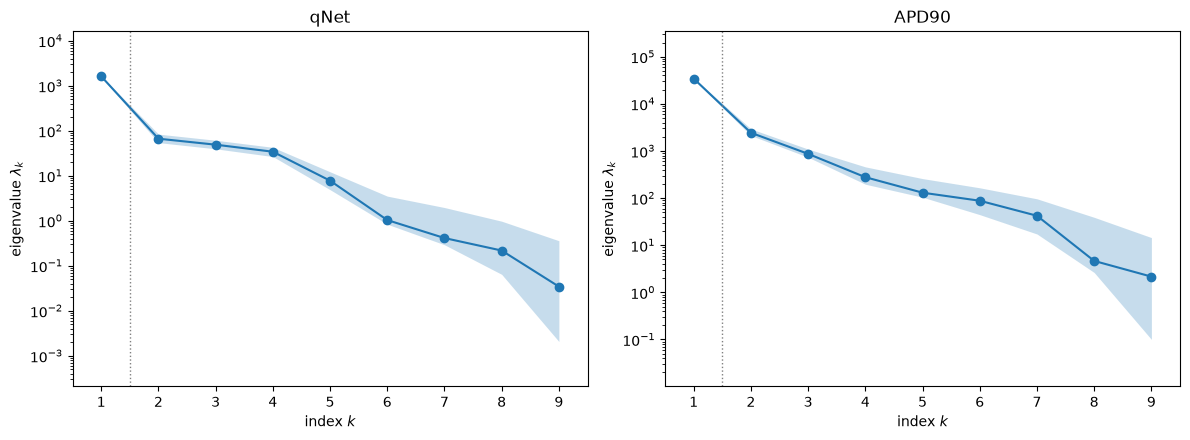

In [7]:
QA, QB = 'qNet', 'APD90'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(subs[QA], ax=axes[0])
ac.plotting.plot_eigenvalues(subs[QB], ax=axes[1])
axes[0].set_title('qNet')
axes[1].set_title('APD90')
fig.tight_layout()
plt.close(fig)
for q in (QA, QB, 'peakCa'):
    lam, b = subs[q].eigenvalues, subs[q].bootstrap_eigenvalues
    lo, hi = np.percentile(b[:, 0] / b[:, 1], [2.5, 97.5])
    lo2, hi2 = np.percentile(b[:, 1] / b[:, 2], [2.5, 97.5])
    print(f'{q}: eigenvalues {np.array2string(lam[:4], precision=4)} ...; lambda1/lambda2 = {lam[0] / lam[1]:.1f} '
          f'(bootstrap 95% [{lo:.1f}, {hi:.1f}]), lambda2/lambda3 = {lam[1] / lam[2]:.1f} ([{lo2:.1f}, {hi2:.1f}])')
fig

The leading eigenvalue dominates for all three features: $\lambda_1/\lambda_2 = 24.3$ for qNet (bootstrap
95 % interval [19.3, 29.6]), 14.1 for APD90 ([11.6, 15.8]) and 46.1 for peakCa ([36.0, 54.1]). After
the first gap the spectrum is flat for qNet and peakCa ($\lambda_2/\lambda_3$ = 1.4 and 1.5), so no second
direction stands out; APD90 has a smaller second gap ($\lambda_2/\lambda_3 = 2.8$).

#### Subspace errors

qNet: bootstrap mean subspace distance, k = 1..4: [0.016 0.245 0.243 0.119]
APD90: bootstrap mean subspace distance, k = 1..4: [0.021 0.098 0.152 0.34 ]


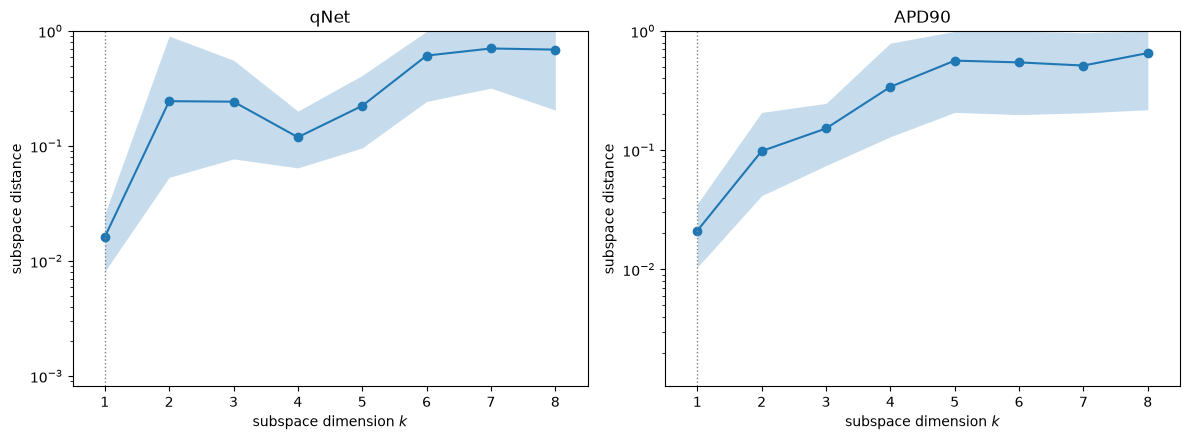

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_subspace_errors(subs[QA], ax=axes[0])
ac.plotting.plot_subspace_errors(subs[QB], ax=axes[1])
axes[0].set_title('qNet')
axes[1].set_title('APD90')
fig.tight_layout()
plt.close(fig)
for q in (QA, QB):
    print(f'{q}: bootstrap mean subspace distance, k = 1..4:',
          np.array2string(subs[q].bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The one-dimensional subspace is well determined: its bootstrap mean distance is 0.016 for qNet and 0.021
for APD90. For qNet the two-dimensional subspace is not (0.245), because $\lambda_2$ and $\lambda_3$ are close
($\lambda_2/\lambda_3 = 1.4$); for APD90 it is moderately well determined (0.098, $\lambda_2/\lambda_3 = 2.8$).

#### Eigenvectors

qNet w1: bINa -0.37, bINaL +0.63, bIto -0.03, bIKs -0.12, bICaL +0.40, bIK1 -0.03, sbIKr -0.52, Vhalf -0.16, Ku -0.01
qNet w2: bINa -0.29, bINaL +0.35, bIto +0.01, bIKs -0.22, bICaL +0.13, bIK1 -0.02, sbIKr +0.83, Vhalf -0.18, Ku -0.01
APD90 w1: bINa +0.07, bINaL -0.23, bIto +0.00, bIKs +0.15, bICaL -0.18, bIK1 +0.21, sbIKr +0.88, Vhalf +0.25, Ku +0.01
APD90 w2: bINa -0.09, bINaL -0.10, bIto -0.00, bIKs +0.29, bICaL -0.04, bIK1 +0.31, sbIKr -0.38, Vhalf +0.81, Ku +0.00
peakCa w1: bINa +0.58, bINaL -0.02, bIto -0.03, bIKs +0.02, bICaL -0.81, bIK1 -0.01, sbIKr +0.06, Vhalf +0.01, Ku -0.00
peakCa w2: bINa -0.81, bINaL +0.02, bIto -0.03, bIKs -0.03, bICaL -0.57, bIK1 -0.01, sbIKr +0.10, Vhalf -0.03, Ku -0.06
|w1(qNet) . w1(APD90)| = 0.77, an angle of 40 degrees
rows with Ku < 0.01 /ms: 3; Ku < 0.1 /ms: 22 (of 224)


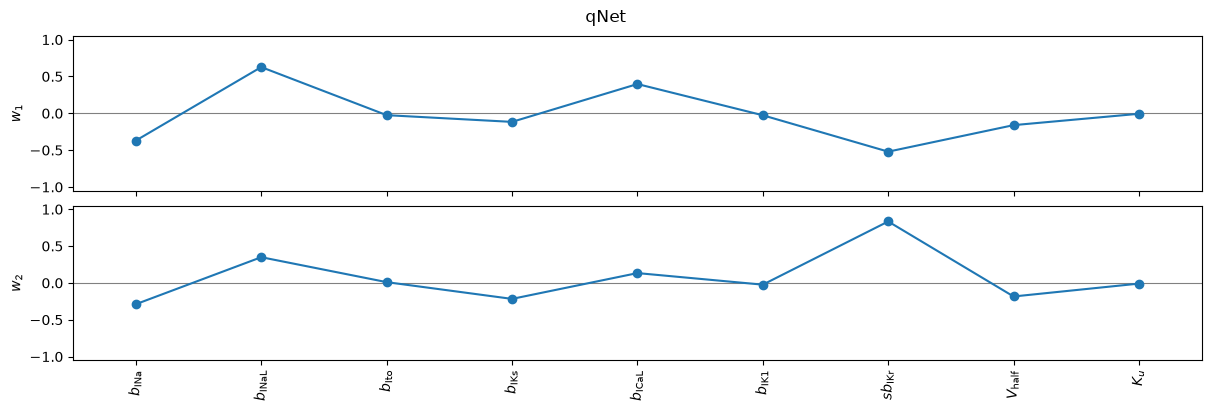

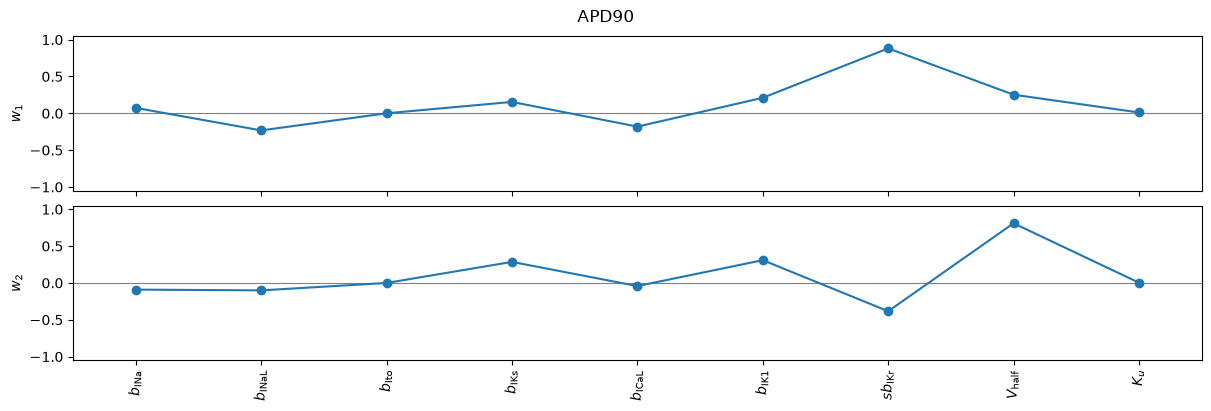

In [9]:
fig1, _ = ac.plotting.plot_eigenvectors(subs[QA], indices=[0, 1], labels=labels, figsize=(12, 4))
fig1.suptitle('qNet')
fig2, _ = ac.plotting.plot_eigenvectors(subs[QB], indices=[0, 1], labels=labels, figsize=(12, 4))
fig2.suptitle('APD90')
plt.close(fig1)
plt.close(fig2)
for q in (QA, QB, 'peakCa'):
    for c in (0, 1):
        print(f'{q} w{c + 1}: ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(NAMES, subs[q].W[:, c])))
c12 = abs(subs[QA].W[:, 0] @ subs[QB].W[:, 0])
print(f'|w1(qNet) . w1(APD90)| = {c12:.2f}, an angle of {np.degrees(np.arccos(c12)):.0f} degrees')
Ku = X[:, NAMES.index('Ku')]
print(f'rows with Ku < 0.01 /ms: {int(np.sum(Ku < 0.01))}; Ku < 0.1 /ms: {int(np.sum(Ku < 0.1))} (of {M})')
display(fig1)
fig2

qNet's first direction mixes four inputs: block of late Na current (+0.63), the static hERG block sbIKr
(−0.52), block of ICaL (+0.40) and block of fast Na current (−0.37); qNet rises with INaL and ICaL block and
falls with hERG and INa block. APD90's is mostly sbIKr (+0.88), with Vhalf (+0.25) next. peakCa's is
block of ICaL (−0.81) and of INa (+0.58). The two hERG kinetic inputs matter little: Ku has weight at most
0.01 in the first direction of all three, and Vhalf at most 0.25. For Ku this reading depends on the design:
Ku is uniform on a linear scale on [1e-5, 1] ms⁻¹ (the paper's box), so only 3 of the 224 rows have
Ku < 0.01 ms⁻¹ (22 below 0.1). The slow-binding, slow-unbinding end, where the paper's Fig. 1 places the
smallest IKr reduction at a given sbIKr (Ku = 1e-5, Vhalf = −200), is barely sampled. The second
directions are shown for completeness only: for qNet $\lambda_2/\lambda_3 = 1.4$, so its $w_2$ is an
arbitrary direction within span($w_2$, $w_3$) (the 2-D subspace distance is 0.245, cell 21). The first directions of qNet and APD90
are about 40° apart ($|w_1^\top w_1| = 0.77$), consistent with the paper's finding that the two metrics depend on
different inputs although they are correlated across the CiPA drugs.

#### Sufficient summary plots

qNet: range [-1.8, 125.4] nC/uF; corr(y1, f) = +0.986, corr(y2, f) = +0.023
APD90: range [202.9, 779.3] ms; corr(y1, f) = +0.974, corr(y2, f) = +0.041
peakCa: range [101.2, 482.6] nM; corr(y1, f) = +0.949, corr(y2, f) = +0.050


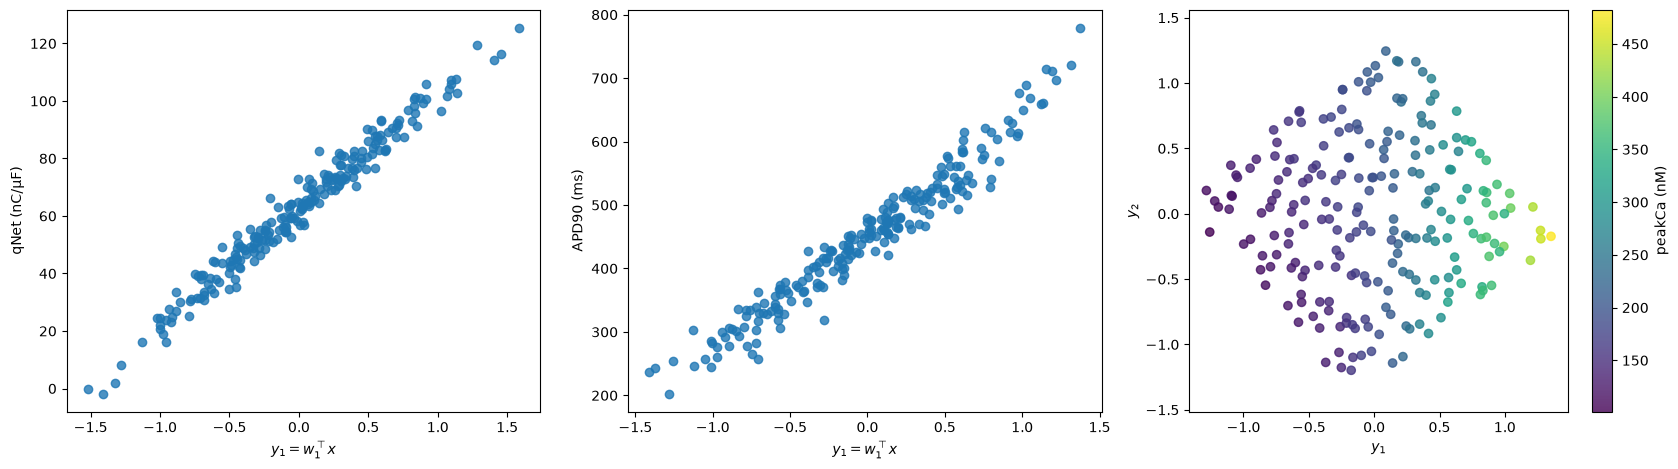

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ac.plotting.plot_sufficient_summary(subs[QA], X=X, f=F[QA], dims=1, qoi_label='qNet (nC/µF)', ax=axes[0])
ac.plotting.plot_sufficient_summary(subs[QB], X=X, f=F[QB], dims=1, qoi_label='APD90 (ms)', ax=axes[1])
ac.plotting.plot_sufficient_summary(ac.with_dimension(subs['peakCa'], 2), X=X, f=F['peakCa'], dims=2,
                                    qoi_label='peakCa (nM)', ax=axes[2])
fig.tight_layout()
plt.close(fig)
for q in (QA, QB, 'peakCa'):
    y = XN @ subs[q].W[:, :2]
    print(f'{q}: range [{F[q].min():.1f}, {F[q].max():.1f}] {UNITS[q]}; corr(y1, f) = {np.corrcoef(y[:, 0], F[q])[0, 1]:+.3f}, '
          f'corr(y2, f) = {np.corrcoef(y[:, 1], F[q])[0, 1]:+.3f}')
fig

Against $y_1$ the features fall close to one curve: corr$(y_1, f)$ = +0.986 for qNet (range −1.8 to 125.4
nC/µF), +0.974 for APD90 (202.9 to 779.3 ms) and +0.949 for peakCa. For peakCa the two-dimensional plot shows the
remaining variation; the correlation with $y_2$ alone is only +0.050, so it is a curvature effect, not a second
linear trend. The $y_2$ axis is not unique: for peakCa $\lambda_2/\lambda_3 = 1.5$ (bootstrap 95 % [1.1, 2.7]),
so $w_2$ is an arbitrary direction within span($w_2$, $w_3$).

## Surrogates on the active variables

Polynomials of degree 3 in $y_1$, and in $(y_1, y_2)$, fitted by least squares; the leave-one-out $R^2$
is computed by the hat-matrix formula (`loo_r_squared`). The plot shows the one-variable fit for qNet.

QoI          cubic in y1  cubic in (y1, y2)


qNet               0.972              0.980
APD90              0.951              0.977
APD50              0.948              0.974
peakVm             0.935              0.977
diastolicCa        0.979              0.990
peakCa             0.977              0.990
CaTD50             0.742              0.956
CaTD90             0.878              0.964


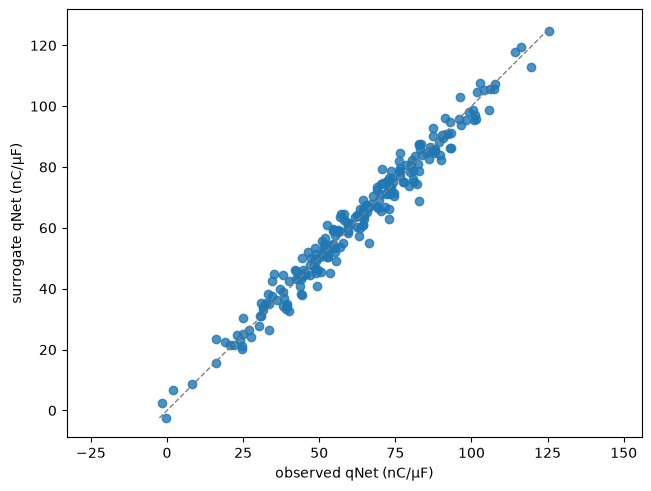

In [11]:
print(f"{'QoI':12s} {'cubic in y1':>11s} {'cubic in (y1, y2)':>18s}")
r2 = {}
for q in QOIS:
    s1 = ac.fit_surrogate(X=X, f=F[q], space=space, subspace=ac.with_dimension(subs[q], 1), kind='poly', degree=3)
    s2 = ac.fit_surrogate(X=X, f=F[q], space=space, subspace=ac.with_dimension(subs[q], 2), kind='poly', degree=3)
    r2[q] = (s1.loo_r_squared, s2.loo_r_squared)
    if q == QA:
        surA = s1
    print(f'{q:12s} {r2[q][0]:11.3f} {r2[q][1]:18.3f}')
fig, ax = ac.plotting.plot_surrogate_fit(surA, X=X, f=F[QA], qoi_label='qNet (nC/µF)')
plt.close(fig)
fig

A cubic in $y_1$ has a leave-one-out $R^2$ of 0.972 for qNet, 0.951 for APD90 and 0.977 for peakCa; adding
$y_2$ raises these to 0.980, 0.977 and 0.990. The weakest one-variable fit is CaTD50 (0.742), the feature with
the smallest first gap and the lowest linear $R^2$ (0.751); with its second active variable, as the ratio rule
chooses, it rises to 0.956. The two borderline features also gain from $y_2$: CaTD90 from 0.878 to 0.964 and
peakVm from 0.935 to 0.977.

## Comparison with the paper

The paper has no active subspace. It reports first-order and total Sobol' indices from 10,000 Saltelli
runs as bar charts (Fig. 4) with a few numbers in the text (p. 8), and the linear-regression $R^2$ of
each feature (Table 4). With 224 runs a Saltelli estimate is not possible, so the cell below computes the
Sobol' indices of the least-squares quadratic in the nine inputs (exact for that quadratic under the
uniform law), with bootstrap 95 % intervals over the rows. They describe the quadratic surrogate, not the
model, wherever the quadratic misfits.

In [12]:
def quad_sobol(f, rows=None):
    """First-order and total Sobol' indices of the least-squares quadratic in the 9 inputs,
    exact for that quadratic under the uniform law on [-1, 1]^9 (terms g_j z_j, a_j (z_j^2 - 1/3)
    and b_jk z_j z_k are orthogonal with variances g_j^2/3, 4 a_j^2/45, b_jk^2/9)."""
    rows = np.arange(len(f)) if rows is None else rows
    c = np.linalg.lstsq(Q[rows], f[rows], rcond=None)[0]
    m = 9
    g, a, B = c[1:m + 1], np.zeros(m), np.zeros((m, m))
    k = m + 1
    for j in range(m):
        for i in range(j, m):
            if i == j:
                a[j] = c[k]
            else:
                B[j, i] = B[i, j] = c[k]
            k += 1
    V1 = g**2 / 3 + 4 * a**2 / 45
    V2 = B**2 / 9
    V = V1.sum() + np.triu(V2, 1).sum()
    return V1 / V, (V1 + V2.sum(axis=1)) / V


rng = np.random.default_rng(SEED)
boot_rows = [rng.integers(0, M, M) for _ in range(500)]
S1, ST, CI1, CIT = {}, {}, {}, {}
for q in ('qNet', 'APD90', 'peakCa'):
    S1[q], ST[q] = quad_sobol(F[q])
    bs = np.array([np.concatenate(quad_sobol(F[q], r)) for r in boot_rows])
    CI1[q] = np.percentile(bs[:, :9], [2.5, 97.5], axis=0)
    CIT[q] = np.percentile(bs[:, 9:], [2.5, 97.5], axis=0)
    print(f'{q:7s} S1: ' + ', '.join(f'{NAMES[j]} {S1[q][j]:.2f} [{CI1[q][0, j]:.2f}, {CI1[q][1, j]:.2f}]'
                                     for j in np.argsort(-S1[q])[:4]) + f'; sum S1 = {S1[q].sum():.2f}')
    print(f'        ST: ' + ', '.join(f'{NAMES[j]} {ST[q][j]:.2f} [{CIT[q][0, j]:.2f}, {CIT[q][1, j]:.2f}]'
                                     for j in np.argsort(-ST[q])[:4]))
paper_r2 = dict(qNet=0.97, APD90=0.94, peakCa=0.90, APD50=0.94, diastolicCa=0.96, CaTD50=0.83, CaTD90=0.92,
                peakVm=0.88)                                     # Table 4, p. 8
print('\nlinear R2 (in-sample), paper Table 4 vs these data, with bootstrap 95% interval over the rows '
      'and the leave-one-out value:')
R2CI = {}
for q in paper_r2:
    bs = []
    for r in boot_rows:
        A, f = A_lin[r], F[q][r]
        res = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
        bs.append(1 - res @ res / np.sum((f - f.mean())**2))
    R2CI[q] = np.percentile(bs, [2.5, 97.5])
    meets = R2CI[q][0] <= paper_r2[q] + 0.005 and R2CI[q][1] >= paper_r2[q] - 0.005   # paper rounds to 0.01
    print(f'  {q:12s} paper {paper_r2[q]:.2f}  here {r2lin[q]:.3f} [{R2CI[q][0]:.3f}, {R2CI[q][1]:.3f}]  '
          f'LOO {loo_r2(A_lin, F[q]):.3f}  interval meets paper value +- 0.005: {meets}')
# where the linear fit of the Ca-transient durations misses: high ICaL block, low INa block
iNa, iCa = NAMES.index('bINa'), NAMES.index('bICaL')
corner = (X[:, iCa] > 60) & (X[:, iNa] < 20)
amp = F['peakCa'] - F['diastolicCa']
A_int = np.column_stack([A_lin, XN[:, iNa] * XN[:, iCa], XN[:, iNa]**2, XN[:, iCa]**2])
print(f'\nrows with bICaL > 60 % and bINa < 20 %: {int(corner.sum())} of {M}; Ca transient amplitude there '
      f'{amp[corner].min():.1f}-{amp[corner].max():.1f} nM (all rows {amp.min():.1f}-{amp.max():.1f})')
for q in ('CaTD50', 'CaTD90'):
    res = F[q] - A_lin @ np.linalg.lstsq(A_lin, F[q], rcond=None)[0]
    print(f'{q}: linear residuals in those rows {res[corner].min():.0f} to {res[corner].max():.0f} ms '
          f'(sd of {q} {F[q].std():.1f} ms), {np.sum(res[corner]**2) / np.sum(res**2):.2f} of the residual sum of '
          f'squares; R2 with bINa*bICaL, bINa^2, bICaL^2 added: {lin_r2(F[q]):.3f} -> '
          f'{1 - np.sum((F[q] - A_int @ np.linalg.lstsq(A_int, F[q], rcond=None)[0])**2) / np.sum((F[q] - F[q].mean())**2):.3f}')

qNet    S1: bINaL 0.39 [0.38, 0.41], sbIKr 0.26 [0.25, 0.27], bICaL 0.15 [0.15, 0.16], bINa 0.13 [0.13, 0.14]; sum S1 = 0.99
        ST: bINaL 0.40 [0.39, 0.41], sbIKr 0.27 [0.26, 0.28], bICaL 0.16 [0.15, 0.16], bINa 0.14 [0.13, 0.14]


APD90   S1: sbIKr 0.73 [0.72, 0.74], Vhalf 0.07 [0.06, 0.08], bINaL 0.06 [0.05, 0.07], bIK1 0.05 [0.04, 0.05]; sum S1 = 0.98
        ST: sbIKr 0.75 [0.74, 0.77], Vhalf 0.07 [0.07, 0.08], bINaL 0.06 [0.06, 0.07], bIK1 0.05 [0.05, 0.06]


peakCa  S1: bICaL 0.66 [0.64, 0.66], bINa 0.27 [0.26, 0.28], sbIKr 0.01 [0.00, 0.01], bIto 0.00 [0.00, 0.00]; sum S1 = 0.93
        ST: bICaL 0.72 [0.71, 0.73], bINa 0.33 [0.32, 0.35], sbIKr 0.01 [0.01, 0.01], bINaL 0.00 [0.00, 0.00]

linear R2 (in-sample), paper Table 4 vs these data, with bootstrap 95% interval over the rows and the leave-one-out value:
  qNet         paper 0.97  here 0.973 [0.964, 0.980]  LOO 0.970  interval meets paper value +- 0.005: True
  APD90        paper 0.94  here 0.950 [0.940, 0.962]  LOO 0.945  interval meets paper value +- 0.005: True
  peakCa       paper 0.90  here 0.904 [0.895, 0.922]  LOO 0.894  interval meets paper value +- 0.005: True
  APD50        paper 0.94  here 0.950 [0.939, 0.963]  LOO 0.945  interval meets paper value +- 0.005: True
  diastolicCa  paper 0.96  here 0.960 [0.951, 0.971]  LOO 0.956  interval meets paper value +- 0.005: True


  CaTD50       paper 0.83  here 0.751 [0.701, 0.816]  LOO 0.725  interval meets paper value +- 0.005: False
  CaTD90       paper 0.92  here 0.870 [0.842, 0.904]  LOO 0.856  interval meets paper value +- 0.005: False
  peakVm       paper 0.88  here 0.882 [0.865, 0.909]  LOO 0.869  interval meets paper value +- 0.005: True

rows with bICaL > 60 % and bINa < 20 %: 14 of 224; Ca transient amplitude there 43.4-76.9 nM (all rows 43.4-406.7)
CaTD50: linear residuals in those rows -113 to 20 ms (sd of CaTD50 71.5 ms), 0.23 of the residual sum of squares; R2 with bINa*bICaL, bINa^2, bICaL^2 added: 0.751 -> 0.857
CaTD90: linear residuals in those rows -99 to 3 ms (sd of CaTD90 81.6 ms), 0.20 of the residual sum of squares; R2 with bINa*bICaL, bINa^2, bICaL^2 added: 0.870 -> 0.928


| quantity | paper | notebook |
|---|---|---|
| linear $R^2$, in-sample (Table 4): qNet, APD90, peakCa | 0.97, 0.94, 0.90 | 0.97, 0.95, 0.90 |
| linear $R^2$, in-sample: APD50, diastolicCa, peakVm | 0.94, 0.96, 0.88 | 0.95, 0.96, 0.88 |
| linear $R^2$, in-sample: CaTD50, CaTD90 (bootstrap 95 %) | 0.83, 0.92 | 0.75 [0.701, 0.816], 0.87 [0.842, 0.904] |
| linear $R^2$, leave-one-out: qNet, APD90, peakCa, CaTD50, CaTD90 | not reported | 0.970, 0.945, 0.894, 0.725, 0.856 |
| features with $R^2 < 0.91$ | p. 8 text: CaTD90 and peakCa; Table 4: CaTD50, peakCa, peakVm | CaTD50, CaTD90, peakVm, peakCa |
| qNet $S_1$: bINaL, sbIKr, bICaL, bINa (p. 8) | 40 %, 26 %, 16 %, 13 % | 0.39, 0.26, 0.15, 0.13 |
| APD90 $S_1$ of sbIKr (p. 8) | "more than 70 %" | 0.73 [0.72, 0.74] |
| peakCa $S_1$ of bICaL (p. 8) | "around 0.6" | 0.66 [0.64, 0.66] |
| peakCa: $S_1$, $S_T$ of bINa; $S_T$ of bICaL (Fig. 4, read off the bars) | ≈ 0.28, ≈ 0.33; ≈ 0.75 | 0.27, 0.33; 0.72 |
| APD90: $S_1$ of Vhalf, $S_T$ of sbIKr (Fig. 4, read off the bars) | ≈ 0.08, ≈ 0.77 | 0.07, 0.75 |
| $S_1$ vs $S_T$ for qNet, APD90 | "small differences" | sums of $S_1$ 0.99, 0.98 |
| active subspace dimension and $\lambda_1/\lambda_2$ | not reported | $n = 1$: qNet 24.3, APD90 14.1, peakCa 46.1; $n = 2$: CaTD50 ($\lambda_2/\lambda_3$ 12.7) |
| EAD runs in Virtual Drug Population I | not reported (EADs only with added hERG block) | 0 of 224 |

The indices here are those of the quadratic surrogate, and their intervals reflect only row resampling;
the Saltelli estimates of the paper carry their own Monte Carlo error, which the paper does not print.
The agreement supports the paper's reading that these metrics are close to linear in the channel blocks;
the active subspace adds that most of them are close to a function of a single linear combination of them,
with CaTD50 needing two and CaTD90 and peakVm borderline.

Two in-sample linear $R^2$ values are lower here than in Table 4: CaTD50 0.751 against 0.83 and CaTD90 0.870
against 0.92. Both paper values lie outside the bootstrap 95 % intervals over the rows ([0.701, 0.816] and
[0.842, 0.904]), even allowing for the paper's rounding to 0.01, while the other six intervals meet the paper's
values (APD90's at its lower end, 0.940 against 0.94), so the shortfall is a difference of model or feature
definition, not sampling noise. It cannot come from the solver tolerance (at most 3.7e-4 relative, DATA.md) or
from the FDA code's 1 ms output grid (at most 1 ms against standard deviations of 71.5 and 81.6 ms). The misfit
is concentrated where ICaL block is high and INa block low (bICaL > 60 %, bINa < 20 %): 14 of the 224 rows, with a
small Ca transient (43.4–76.9 nM), carry 0.23 of the CaTD50 residual sum of squares, with residuals down to
−113 ms. Adding bINa·bICaL and the two squares raises the $R^2$ from 0.751 to 0.857 (CaTD50) and from 0.870 to
0.928 (CaTD90). Plausible causes
are the authors' unpublished CaTD definition (start time, baseline, which beat) or their "minor modifications"
of the FDA code; the paper does not say. The paper is also inconsistent here: its p. 8 text says that "CaTD90
and peakCa were the only features that had R² values of less than 0.91", while its Table 4 gives CaTD90 0.92,
CaTD50 0.83 and peakVm 0.88.

## References

- J. Parikh, P. Di Achille, J. Kozloski, V. Gurev. Global sensitivity analysis of ventricular myocyte
  model-derived metrics for proarrhythmic risk assessment. *Frontiers in Pharmacology* 10:1054, 2019.
  [doi:10.3389/fphar.2019.01054](https://doi.org/10.3389/fphar.2019.01054)
- T. O'Hara, L. Virág, A. Varró, Y. Rudy. Simulation of the undiseased human cardiac ventricular action
  potential: model formulation and experimental validation. *PLoS Computational Biology* 7(5):e1002061,
  2011. [doi:10.1371/journal.pcbi.1002061](https://doi.org/10.1371/journal.pcbi.1002061)
- Z. Li, S. Dutta, J. Sheng, P. N. Tran, W. Wu, K. Chang, T. Mdluli, D. G. Strauss, T. Colatsky. Improving
  the in silico assessment of proarrhythmia risk by combining hERG (human ether-à-go-go-related gene)
  channel–drug binding kinetics and multichannel pharmacology. *Circulation: Arrhythmia and
  Electrophysiology* 10(2):e004628, 2017.
  [doi:10.1161/CIRCEP.116.004628](https://doi.org/10.1161/CIRCEP.116.004628)
- S. Dutta, K. C. Chang, K. A. Beattie, J. Sheng, P. N. Tran, W. W. Wu, M. Wu, D. G. Strauss, T. Colatsky,
  Z. Li. Optimization of an in silico cardiac cell model for proarrhythmia risk assessment. *Frontiers in
  Physiology* 8:616, 2017. [doi:10.3389/fphys.2017.00616](https://doi.org/10.3389/fphys.2017.00616)
- K. C. Chang, S. Dutta, G. R. Mirams, K. A. Beattie, J. Sheng, P. N. Tran, M. Wu, W. W. Wu, T. Colatsky,
  D. G. Strauss, Z. Li. Uncertainty quantification reveals the importance of data variability and
  experimental design considerations for in silico proarrhythmia risk assessment. *Frontiers in
  Physiology* 8:917, 2017. [doi:10.3389/fphys.2017.00917](https://doi.org/10.3389/fphys.2017.00917)
  (the FDA CiPA code, https://github.com/FDA/CiPA)
- M. Clerx, P. Collins, E. de Lange, P. G. A. Volders. Myokit: a simple interface to cardiac cellular
  electrophysiology. *Progress in Biophysics and Molecular Biology* 120(1–3):100–114, 2016.
  [doi:10.1016/j.pbiomolbio.2015.12.008](https://doi.org/10.1016/j.pbiomolbio.2015.12.008)
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*.
  SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

The paper states no funding.

In [13]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 7 s
